# Investigate Hotel Business Using Data Visualisation

## Stage 0 : Problem Statement

• **Why it matters**: booking behaviour drives occupancy and revenue, and cancellations leave rooms empty that could have been sold.

• **Decisions it improves**: pricing, staffing for peak months, cancellation and deposit policies, overbooking levels, and marketing timing.

• **The three questions**: which hotel type is booked most, whether length of stay affects cancellation rate, and whether lead time affects cancellation rate.

• **Objective and Deliverable**:  a set of clear visualisations plus data-backed recommendations to raise bookings and reduce cancellations.

## Stage 1 : Data Preprocessing

### 1.1 Data Overview

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("hotel_bookings_data.csv")
print(df.shape)

(119390, 29)


In [9]:
print(df["arrival_date_year"].value_counts().sort_index())

2017    21996
2018    56707
2019    40687
Name: arrival_date_year, dtype: int64


In [10]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_weekdays_nights,adults,...,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status
0,Resort Hotel,0,342,2017,September,27,1,0,0,2,...,3,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
1,Resort Hotel,0,737,2017,September,27,1,0,0,2,...,4,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
2,Resort Hotel,0,7,2017,September,27,1,0,1,1,...,0,No Deposit,NaN,NaN,0,Personal,75.0,0,0,Check-Out
3,Resort Hotel,0,13,2017,September,27,1,0,1,1,...,0,No Deposit,304.0,NaN,0,Personal,75.0,0,0,Check-Out
4,Resort Hotel,0,14,2017,September,27,1,0,2,2,...,0,No Deposit,240.0,NaN,0,Personal,98.0,0,1,Check-Out


The columns used for the three questions are : 
hotel, is_canceled, lead_time, arrival_date_month, stays_in_weekend_nights and stays_in_weekdays_nights

### 1.2 Data Assessment

#### Missing Values

In [11]:
df.isna().sum()[df.isna().sum() > 0]

children         4
city           488
agent        16340
company     112593
dtype: int64

In [12]:
df["company"] = df["company"].fillna(0)   # no company = personal booking
df["agent"] = df["agent"].fillna(0)       # no agent = booked directly
df["children"] = df["children"].fillna(0) # most likely no children
df["city"] = df["city"].fillna("Unknown")

In [13]:
df.isna().sum()[df.isna().sum() > 0]

Series([], dtype: int64)

#### Duplicates

In [14]:
df.duplicated().sum()   

33261

The dataset has no booking ID, so identical rows are probably separate bookings with the same details, like group or family rooms. Deleting them would undercount demand. Hence, I have kept the duplicate rows in the dataset as it is.

#### Inconsistent Values

In [15]:
print(df["meal"].value_counts())

Breakfast     92310
Dinner        14463
No Meal       10650
Undefined      1169
Full Board      798
Name: meal, dtype: int64

“Undefined” (1,169 rows) means no meal package was recorded, so it fits with “No Meal”.

In [21]:
df["meal"] = df["meal"].replace("Undefined", "No Meal")
print(df["meal"].value_counts())

Breakfast     92310
Dinner        14463
No Meal       11819
Full Board      798
Name: meal, dtype: int64


#### Anomalies

In [22]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
print((df["adr"] < 0).sum(), (df["total_guests"] == 0).sum())  # 1, 180

df = df[(df["adr"] >= 0) & (df["adr"] < 5000) & (df["total_guests"] > 0)]
df["total_stay"] = df["stays_in_weekend_nights"] + df["stays_in_weekdays_nights"]
print(df.shape)

1 180
(119208, 31)


- Negative adr (1 row) and the 5,400 outlier: a room price can’t be negative, and 5,400 is far above the next-highest rates, so I have treated both as data entry errors.
- Zero-guest bookings (180 rows): a booking with no guests isn’t a real stay.
- Zero adr (about 1,959 rows): They’re plausibly complimentary stays, so I decided to keep them.

## Stage 2: Data Analysis
### 2.1 Monthly Booking Analysis by Hotel Type
#### **Q1. Which hotel type is booked more often?**

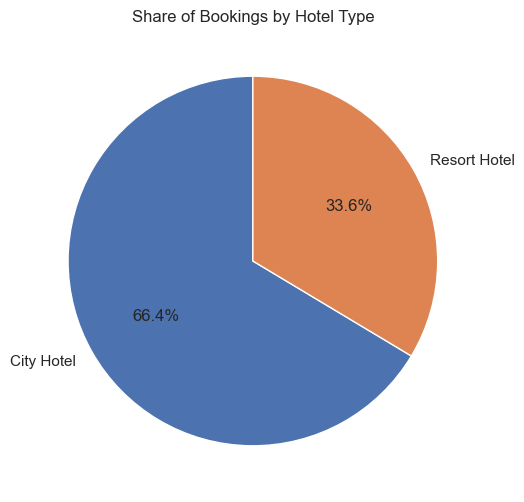

In [23]:
share = df["hotel"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(share, labels=share.index, autopct="%1.1f%%", startangle=90,
        colors=["#4C72B0", "#DD8452"])
plt.title("Share of Bookings by Hotel Type")
plt.show()

*Figure 1: Share of total bookings between City Hotel and Resort Hotel.*

City Hotel receives about **66.4%** of all bookings, compared with **33.6%** for
Resort Hotel. City Hotel is booked roughly **twice as often**.

#### **Q2. Which months are busiest and which are quietest?**

September and October appear in three years of data, while all other months
appear in only two. To compare months fairly, I divided each month's bookings
by the number of years it appears in, giving the average bookings per year.

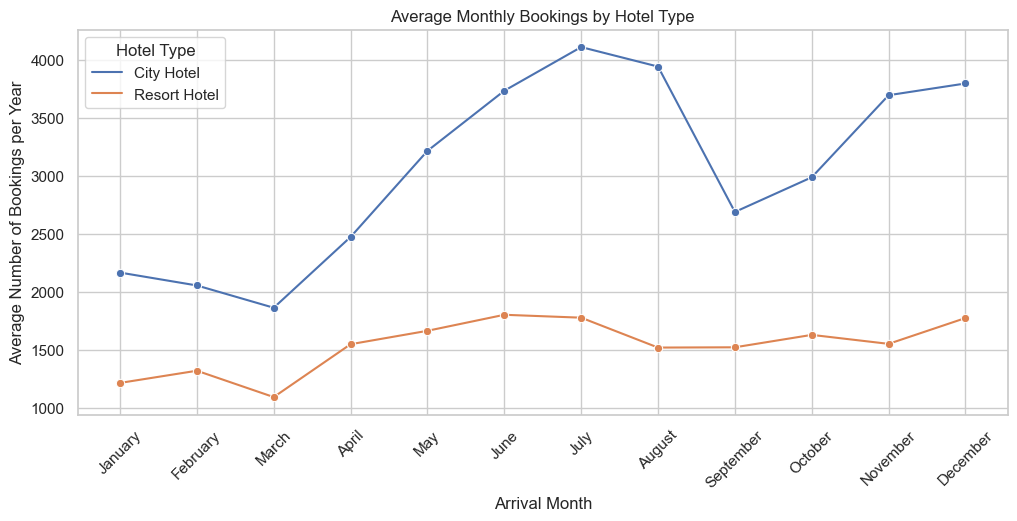

In [24]:
months = ["January","February","March","April","May","June","July",
          "August","September","October","November","December"]

monthly = (df.groupby(["hotel", "arrival_date_month"])
             .agg(bookings=("hotel", "size"),
                  years=("arrival_date_year", "nunique"))
             .reset_index())
monthly["avg_bookings"] = monthly["bookings"] / monthly["years"]
monthly["arrival_date_month"] = pd.Categorical(monthly["arrival_date_month"],
                                               categories=months, ordered=True)
monthly = monthly.sort_values("arrival_date_month")

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="arrival_date_month", y="avg_bookings",
             hue="hotel", marker="o")
plt.title("Average Monthly Bookings by Hotel Type")
plt.xlabel("Arrival Month")
plt.ylabel("Average Number of Bookings per Year")
plt.xticks(rotation=45)
plt.legend(title="Hotel Type")
plt.show()

*Figure 2: Average number of bookings per month for each hotel type, adjusted
for the number of years each month appears in the data.*

- **City Hotel** is busiest in **July and August** (about 4,000 bookings a month)
  and stays high from June to December.
- **Resort Hotel** has a flatter pattern, peaking in **June, July and December**
  (about 1,800 bookings a month).
- **January to March** is the quietest period for both hotels, with **March**
  the lowest month.

#### **Q3. What might explain the seasonal pattern?**

- **Summer holidays:** schools close in mid-year, so families travel more in
  June–August, which creates the main peak for both hotels.
- **Year-end holidays:** Christmas and New Year raise December bookings,
  especially at the Resort Hotel, a popular leisure choice.
- **Post-holiday slowdown:** after the December holidays, people have spent
  their travel budgets and leave, so January–March is quiet.
- **Business travel:** City Hotel also serves business travellers year-round,
  which keeps its bookings consistently higher than the Resort Hotel's.

#### **Q4. What decisions could the hotel make based on this trend?**

- **Dynamic pricing:** raise room rates during peak months (June–August,
  December) and offer discounts or packages in January–March.
- **Staffing:** hire seasonal staff before the peaks; schedule staff leave in
  the quiet months.
- **Maintenance:** plan renovations and repairs for January–March, when fewer
  rooms are occupied.
- **Marketing:** run promotions in late autumn to fill the early-year low
  season, for example winter getaway deals for the Resort Hotel.

### 2.2 Impact of Stay Duration on Cancellation Rate
#### **Q1. Which hotel type is cancelled more often?**

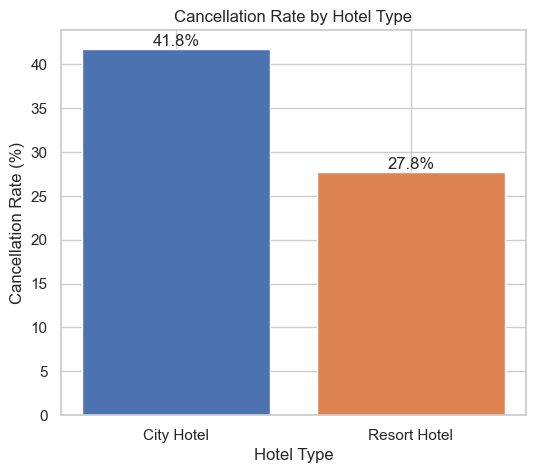

In [26]:
cancel_rate = df.groupby("hotel")["is_canceled"].mean() * 100

plt.figure(figsize=(6, 5))
bars = plt.bar(cancel_rate.index, cancel_rate.values,
               color=["#4C72B0", "#DD8452"])
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()

*Figure 3: Percentage of bookings cancelled at each hotel type.*

City Hotel has a cancellation rate of **41.8%**, compared with **27.8%** for
Resort Hotel. City Hotel bookings are cancelled about **1.5 times as often**.

#### **Q2. How does the cancellation rate change as length of stay increases?**

Stays of 1–7 nights are shown individually. Longer stays are grouped by week,
because each individual length beyond 7 nights has very few bookings.
I excluded 0-night bookings (645 rows) and stays over 30 nights (21 rows),
since these groups are too small or unusual to give reliable rates.

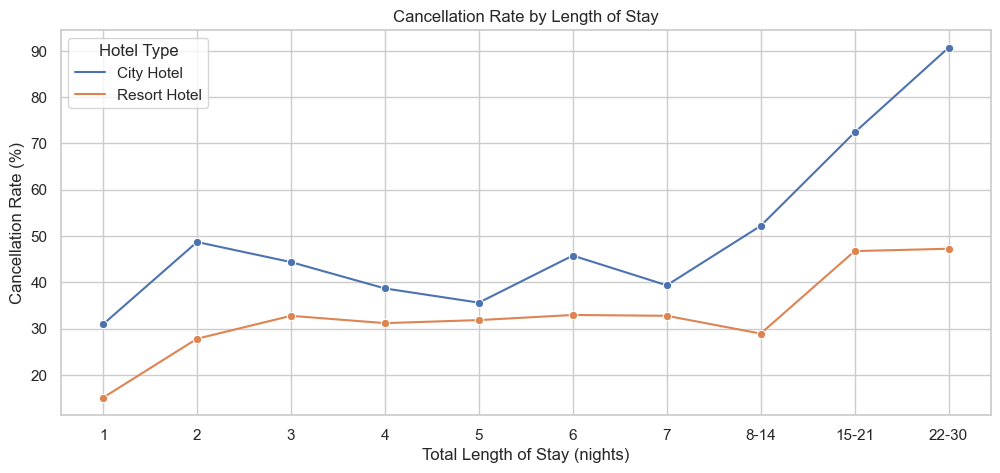

In [27]:
bins = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 30]
labels = ["1", "2", "3", "4", "5", "6", "7", "8-14", "15-21", "22-30"]
df["stay_group"] = pd.cut(df["total_stay"], bins=bins, labels=labels)

stay_cancel = (df.dropna(subset=["stay_group"])
                 .groupby(["hotel", "stay_group"], observed=True)["is_canceled"]
                 .mean().mul(100).reset_index())

plt.figure(figsize=(12, 5))
sns.lineplot(data=stay_cancel, x="stay_group", y="is_canceled",
             hue="hotel", marker="o")
plt.title("Cancellation Rate by Length of Stay")
plt.xlabel("Total Length of Stay (nights)")
plt.ylabel("Cancellation Rate (%)")
plt.legend(title="Hotel Type")
plt.show()

*Figure 4: Cancellation rate for each length of stay, by hotel type.*

- **City Hotel:** cancellations rise from **31% for 1-night stays** to about
  **40–49% for 2–7 nights**, then climb sharply to **52% (8–14 nights)**,
  **72% (15–21 nights)** and **91% (22–30 nights)**.
- **Resort Hotel:** cancellations rise from **15% for 1-night stays** to a
  stable **28–33% for 2–14 nights**, then jump to about **47% for stays
  longer than two weeks**.
- Note: groups above 14 nights have few bookings (under 200 each), so those
  rates are less reliable than the shorter-stay rates.

#### **Q3. Is the relationship positive, negative or flat? Does it differ by hotel?**

The relationship is **positive**: longer stays tend to be cancelled more often.
It differs between the two hotels:
- **City Hotel** shows a **strong** positive relationship, especially after
  one week, where cancellations rise steeply.
- **Resort Hotel** is **flatter** in the middle range (2–14 nights) and only
  rises clearly for stays longer than two weeks.

#### **Q4. Why might longer stays be cancelled more often?**

- **Bigger commitment:** a long stay costs more and blocks more days of the
  guest's schedule, so a change in plans or budget is more likely to cancel it.
- **Plans made far in advance:** long trips are often booked early, leaving
  more time for something to change before arrival.
- **Speculative or placeholder bookings:** guests may reserve a long stay to
  hold rooms, then cancel once their plans are confirmed or they find a
  cheaper option.
- **Business or event travel at City Hotel:** long city stays are often tied
  to work projects or events that can be postponed or cancelled.

### 2.3 Impact of Lead Time on Cancellation Rate

#### **Q1. What is lead time, and how does it affect cancellations?**

**Lead time** is the number of days between the date a guest makes a booking
and the date they are due to arrive. A lead time of 0 means the guest booked
on the day of arrival; a lead time of 300 means they booked about 10 months
ahead.

Lead times range from 0 to 737 days, so I grouped them into 30-day
(roughly monthly) intervals, with all bookings made more than a year ahead
combined into one group.

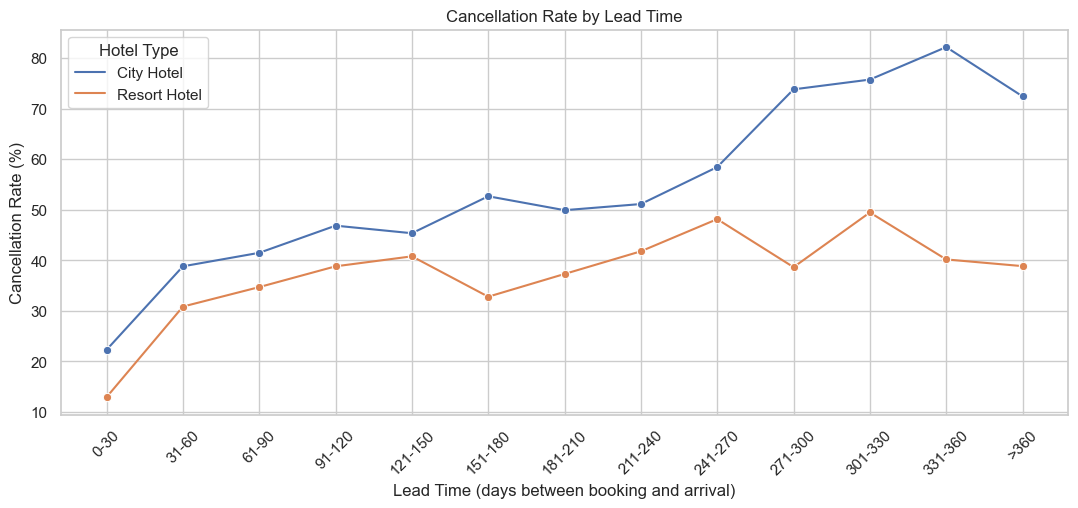

In [28]:
bins = [-1, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360, 1000]
labels = ["0-30", "31-60", "61-90", "91-120", "121-150", "151-180",
          "181-210", "211-240", "241-270", "271-300", "301-330",
          "331-360", ">360"]
df["lead_group"] = pd.cut(df["lead_time"], bins=bins, labels=labels)

lead_cancel = (df.groupby(["hotel", "lead_group"])["is_canceled"]
                 .mean().mul(100).reset_index())
lead_cancel = lead_cancel.sort_values("lead_group")

plt.figure(figsize=(13, 5))
sns.lineplot(data=lead_cancel, x="lead_group", y="is_canceled",
             hue="hotel", marker="o", sort=False)
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Lead Time (days between booking and arrival)")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Hotel Type")
plt.show()

*Figure 5: Cancellation rate for each 30-day lead time group, by hotel type.*

- Both hotels have their **lowest** cancellation rate for bookings made
  **0–30 days** before arrival: **22%** for City Hotel and **13%** for
  Resort Hotel.
- **City Hotel** cancellations rise steadily with lead time, from 22% to
  about 50% at 6 months, then climb sharply to **82% for bookings made
  331–360 days ahead**, the highest point in the chart.
- **Resort Hotel** cancellations rise to about 30–40% once lead time passes
  one month, then stay in a narrower range of **33–50%**, peaking at
  **about 50% for 301–330 days**.

#### **Q2. At what lead time is cancellation lowest and highest?**

- **Lowest:** 0–30 days, for both hotel types (City 22%, Resort 13%).
- **Highest:** 331–360 days at **City Hotel (82%)**. Resort Hotel's highest
  point is lower, at about 50% for 301–330 days.

#### **Q3. Does one hotel type stay more stable across lead times?**

Yes. **Resort Hotel is more stable**: after the first month, its cancellation
rate stays between roughly 33% and 50%. **City Hotel rises sharply**, from
22% for last-minute bookings to over 70% for bookings made more than nine
months ahead.

Possible explanations:
- **Purpose of travel:** resort stays are usually planned holidays, and
  guests who book far ahead tend to be committed to their trip. City Hotel
  serves more business and event travellers, whose plans change often.
- **Placeholder bookings:** city guests, or travel agents booking groups,
  may reserve rooms far in advance to secure availability, then cancel once
  plans are confirmed.
- **Price shopping:** city hotels have many nearby alternatives, so guests
  who book early have more time to find a cheaper option and cancel.
- **Short lead time = firm plans:** a booking made within a month is usually
  for a trip that is already certain, so it is rarely cancelled.

## Stage 3: Summary and Recommendations
### 3.1 Key Findings

**1. Hotel type popularity (Figures 1–2)**
- City Hotel receives about **two-thirds (66.4%)** of all bookings; Resort
  Hotel receives **one-third (33.6%)**.
- Bookings peak in **July–August** for City Hotel and in **June, July and
  December** for Resort Hotel. **January–March** is the quietest period
  for both, with March the lowest month.

**2. Stay duration and cancellations (Figures 3–4)**
- City Hotel bookings are cancelled far more often (**41.8%**) than Resort
  Hotel bookings (**27.8%**).
- Longer stays are cancelled more often. At City Hotel, cancellations rise
  from **31% for 1-night stays** to **52% for 8–14 nights** and over **70%
  for stays longer than two weeks**. Resort Hotel stays flatter (28–33%
  for 2–14 nights) and rises to about 47% only for stays over two weeks.

**3. Lead time and cancellations (Figure 5)**
- Bookings made **within 30 days** of arrival are the least likely to be
  cancelled (City 22%, Resort 13%).
- City Hotel cancellations rise steadily with lead time, reaching **82% for
  bookings made 331–360 days ahead**. Resort Hotel stays within a narrower
  range of about **33–50%**.

### 3.2 Recommendations: Hotel Type and Seasonality

1. **Grow the Resort Hotel in its low season.** Resort bookings fall to
   their lowest in January–March (Figure 2). Offer winter getaway packages,
   such as discounted multi-night stays with meals or activities included,
   promoted in November–December when travellers plan their next trips.

2. **Capitalise on peak months with dynamic pricing.** Both hotels are
   busiest in June–August, and City Hotel stays strong through December
   (Figure 2). Raise room rates during these months, when demand is
   highest, and prioritise direct bookings that the hotel controls.

3. **Plan operations around the seasonal cycle.** Hire seasonal staff
   ahead of the summer and December peaks, and schedule renovations and
   staff leave for January–March, when fewer rooms are occupied.

### 3.3 Recommendations: Stay Duration and Cancellations

1. **Stricter cancellation terms for long stays.** Stays longer than one
   week have the highest cancellation rates, especially at City Hotel
   (52–91%, Figure 4). Require a partial non-refundable deposit, for
   example the first night's charge, for bookings of 8 nights or more.

2. **Discounted non-refundable rates.** Offer a lower price to guests who
   accept no cancellation. Price-sensitive guests get a better deal, and
   the hotel locks in revenue for long stays that might otherwise cancel.

3. **Flexible changes instead of cancellations.** Allow guests to shorten
   a long stay or move their dates for free, rather than cancelling the
   whole booking. The hotel keeps part of the revenue instead of losing
   all of it.

### 3.4 Recommendations: Lead Time and Cancellations

1. **Deposits for far-ahead bookings.** Cancellation rates climb above 70%
   at City Hotel for bookings made more than nine months ahead (Figure 5).
   Require a deposit for bookings made more than six months in advance,
   refundable only up to a set date before arrival.

2. **Reminders before the cancellation deadline.** Email guests at fixed
   points before arrival (for example, 60 and 30 days) to confirm their
   plans. This helps the hotel learn about cancellations early, while
   there is still time to resell the room.

3. **Free rescheduling.** Let guests who booked far ahead change their
   dates without a fee. A guest whose plans change is more likely to
   reschedule than cancel, so the booking is kept.

4. **Early-booking discounts tied to commitment.** Offer a discount for
   booking early only if the guest pays upfront, which rewards early
   planners without encouraging placeholder bookings.

### 3.5 Recommendation with the Biggest Impact

**Requiring deposits for City Hotel bookings made more than six months in
advance** would likely have the biggest impact, for three reasons:

- **Scale:** City Hotel receives two-thirds of all bookings (Figure 1) and
  has the higher cancellation rate (41.8% vs 27.8%, Figure 3), so this is
  where most cancelled bookings occur.
- **Severity:** cancellation rates for City Hotel bookings made more than
  six months ahead range from about 50% to 82% (Figure 5), meaning at least
  half of these bookings are lost.
- **Targeted:** the policy affects only far-ahead bookings, so the
  last-minute bookings that rarely cancel (22%) are not discouraged.

A deposit discourages placeholder bookings and makes guests more committed
to their stay. When cancellations do happen, the hotel keeps part of the
revenue.